# Olist E-Commerce Dataset - Data Exploration

## Project
E-Commerce Data Intelligence Platform

## Objective
Explore and understand the Olist Brazilian E-Commerce dataset
before implementing the ETL pipelines.

## Data Source
Kaggle - Brazilian E-Commerce Public Dataset by Olist

https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

## Analysis
- Dataset structure
- Data types
- Missing values
- Duplicate records
- Primary key uniqueness
- Referential integrity
- Date and business analysis

In [9]:
# Importation des bibliothèques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Libraries successfully imported")

Libraries successfully imported


In [10]:
# Configuration des chemins
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data" / "raw" / "olist").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "olist"

print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATA_DIR)

assert DATA_DIR.exists(), "Dataset directory not found!"

Project root: c:\Users\anash\Desktop\E-Commerce Data Intelligence Platform\ecommerce-data-intelligence
Dataset directory: c:\Users\anash\Desktop\E-Commerce Data Intelligence Platform\ecommerce-data-intelligence\data\raw\olist


In [11]:
# Chargement des données
files = {
    "orders": "olist_orders_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category_translation": "product_category_name_translation.csv"
}

dataframes = {}

for name, filename in files.items():

    file_path = DATA_DIR / filename

    if not file_path.exists():
        raise FileNotFoundError(f"Missing file: {filename}")

    dataframes[name] = pd.read_csv(file_path)

    print(f"{name}: {dataframes[name].shape}")

orders: (99441, 8)
customers: (99441, 5)
order_items: (112650, 7)
products: (32951, 9)
sellers: (3095, 4)
payments: (103886, 5)
reviews: (99224, 7)
geolocation: (1000163, 5)
category_translation: (71, 2)


In [12]:
# Unicité des clés primaires
primary_keys = {
    "orders": ["order_id"],
    "customers": ["customer_id"],
    "order_items": ["order_id", "order_item_id"],
    "products": ["product_id"],
    "sellers": ["seller_id"],
    "payments": ["order_id", "payment_sequential"],
    "reviews": ["review_id"]
}

for table, keys in primary_keys.items():

    df = dataframes[table]

    duplicated_keys = df.duplicated(subset=keys).sum()
    null_keys = df[keys].isnull().sum().sum()

    print(f"\nTable: {table}")
    print(f"Primary key: {keys}")
    print(f"Duplicated keys: {duplicated_keys}")
    print(f"Null key values: {null_keys}")


Table: orders
Primary key: ['order_id']
Duplicated keys: 0
Null key values: 0

Table: customers
Primary key: ['customer_id']
Duplicated keys: 0
Null key values: 0

Table: order_items
Primary key: ['order_id', 'order_item_id']
Duplicated keys: 0
Null key values: 0

Table: products
Primary key: ['product_id']
Duplicated keys: 0
Null key values: 0

Table: sellers
Primary key: ['seller_id']
Duplicated keys: 0
Null key values: 0

Table: payments
Primary key: ['order_id', 'payment_sequential']
Duplicated keys: 0
Null key values: 0

Table: reviews
Primary key: ['review_id']
Duplicated keys: 814
Null key values: 0


In [13]:
# Intégrité référentielle
relationships = [
    ("orders", "customer_id", "customers", "customer_id"),
    ("order_items", "order_id", "orders", "order_id"),
    ("order_items", "product_id", "products", "product_id"),
    ("order_items", "seller_id", "sellers", "seller_id"),
    ("payments", "order_id", "orders", "order_id"),
    ("reviews", "order_id", "orders", "order_id")
]

for child_table, child_col, parent_table, parent_col in relationships:

    child = dataframes[child_table]
    parent = dataframes[parent_table]

    child_values = set(child[child_col].dropna().unique())
    parent_values = set(parent[parent_col].dropna().unique())

    orphan_values = child_values - parent_values

    print(
        f"{child_table}.{child_col} -> "
        f"{parent_table}.{parent_col}"
    )

    print("Unmatched values:", len(orphan_values))
    print("-" * 60)

orders.customer_id -> customers.customer_id
Unmatched values: 0
------------------------------------------------------------
order_items.order_id -> orders.order_id
Unmatched values: 0
------------------------------------------------------------
order_items.product_id -> products.product_id
Unmatched values: 0
------------------------------------------------------------
order_items.seller_id -> sellers.seller_id
Unmatched values: 0
------------------------------------------------------------
payments.order_id -> orders.order_id
Unmatched values: 0
------------------------------------------------------------
reviews.order_id -> orders.order_id
Unmatched values: 0
------------------------------------------------------------


In [14]:
# Visualisation des valeurs manquantes
missing_data = []

for table_name, df in dataframes.items():

    for column in df.columns:

        missing_count = df[column].isnull().sum()

        if missing_count > 0:

            missing_data.append({
                "table": table_name,
                "column": column,
                "missing_count": missing_count,
                "missing_percentage": (
                    missing_count / len(df)
                ) * 100
            })

missing_df = pd.DataFrame(missing_data)

missing_df = missing_df.sort_values(
    by="missing_percentage",
    ascending=False
)

display(missing_df)

,table,column,missing_count,missing_percentage
11,reviews,review_comment_title,87656,88.341530
12,reviews,review_comment_message,58247,58.702532
2,orders,order_delivered_customer_date,2965,2.981668
4,products,product_name_lenght,610,1.851234
3,products,product_category_name,610,1.851234
5,products,product_description_lenght,610,1.851234
6,products,product_photos_qty,610,1.851234
1,orders,order_delivered_carrier_date,1783,1.793023
0,orders,order_approved_at,160,0.160899
8,products,product_length_cm,2,0.006070


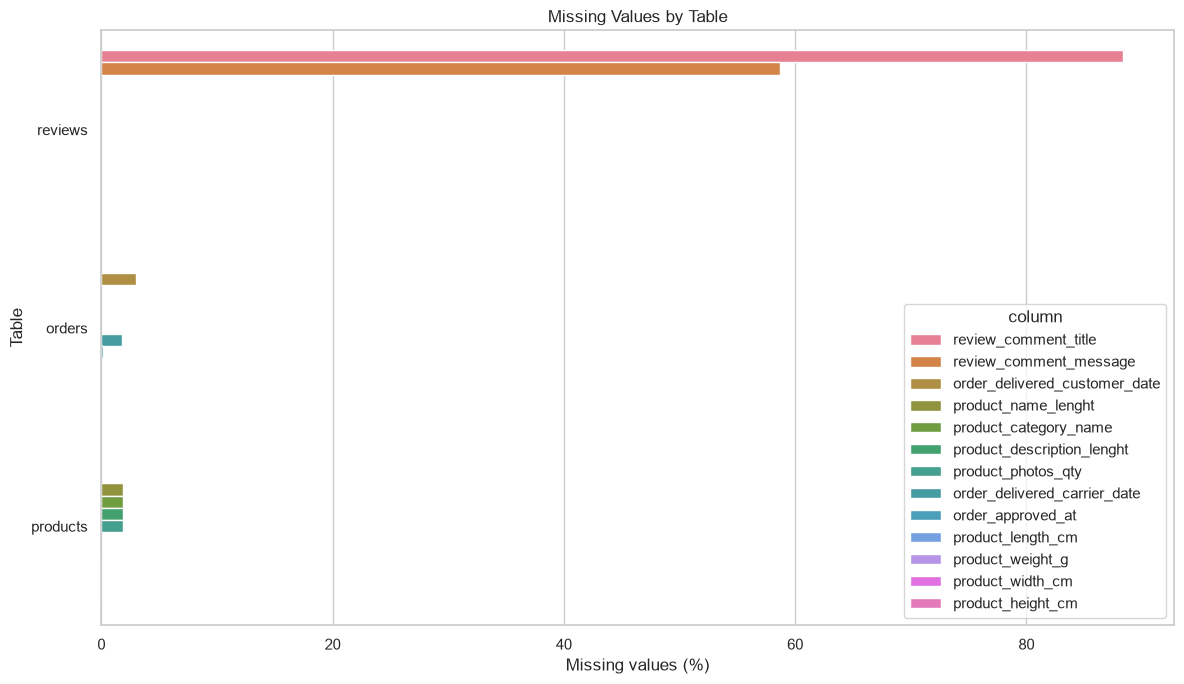

In [15]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=missing_df,
    x="missing_percentage",
    y="table",
    hue="column"
)

plt.title("Missing Values by Table")
plt.xlabel("Missing values (%)")
plt.ylabel("Table")

plt.tight_layout()
plt.show()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

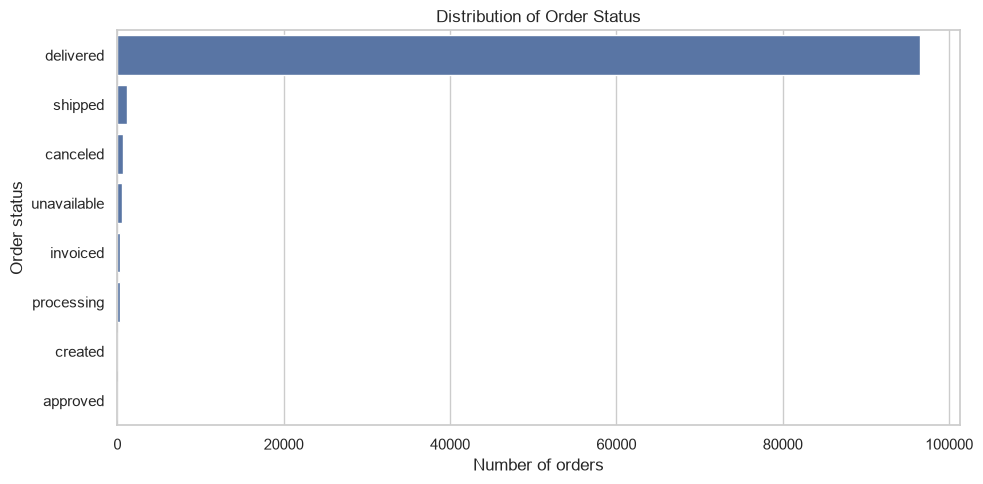

In [16]:
# Analyse des statuts des commandes
orders = dataframes["orders"]

status_counts = orders["order_status"].value_counts()

display(status_counts)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=status_counts.values,
    y=status_counts.index
)

plt.title("Distribution of Order Status")
plt.xlabel("Number of orders")
plt.ylabel("Order status")

plt.tight_layout()
plt.show()

In [17]:
# Analyse des identifiants review_id dupliqués
reviews = dataframes["reviews"]

# Identifier toutes les lignes dont review_id est dupliqué
duplicated_reviews = reviews[
    reviews.duplicated(subset=["review_id"], keep=False)
].copy()

# Trier les résultats
duplicated_reviews = duplicated_reviews.sort_values("review_id")

print("Total duplicated rows:", len(duplicated_reviews))

print(
    "Number of duplicated review IDs:",
    duplicated_reviews["review_id"].nunique()
)

display(duplicated_reviews.head(30))

Total duplicated rows: 1603
Number of duplicated review IDs: 789


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


In [18]:
review_analysis = (
    reviews.groupby("review_id")
    .agg(
        number_of_rows=("order_id", "size"),
        distinct_orders=("order_id", "nunique"),
        distinct_scores=("review_score", "nunique"),
        distinct_creation_dates=("review_creation_date", "nunique"),
        distinct_answers=("review_answer_timestamp", "nunique")
    )
    .query("number_of_rows > 1")
    .sort_values("number_of_rows", ascending=False)
)

display(review_analysis)

,number_of_rows,distinct_orders,distinct_scores,distinct_creation_dates,distinct_answers
review_id,,,,,
4219a80ab469e3fc9901437b73da3f75,3,3,1,1,1
7b606b0d57b078384f0b58eac1d41d78,3,3,1,1,1
0c76e7a547a531e7bf9f0b99cba071c1,3,3,1,1,1
69a1068c3128a14994e3e422e4539e04,3,3,1,1,1
308316408775d1600dad81bd3184556d,3,3,1,1,1
...,...,...,...,...,...
fde2e6abaf5bb64f7407a44741c24dec,2,2,1,1,1
fde5986d35c89aa1b6ce4149de82a0d3,2,2,1,1,1
fe5c833752953fed3209646f1f63b53c,2,2,1,1,1


In [19]:
print(
    "Duplicated review_id + order_id:",
    reviews.duplicated(
        subset=["review_id", "order_id"]
    ).sum()
)

print(
    "Duplicated order_id:",
    reviews.duplicated(
        subset=["order_id"]
    ).sum()
)

Duplicated review_id + order_id: 0
Duplicated order_id: 551


In [20]:
# Statuts et dates manquantes
orders = dataframes["orders"]

orders["delivery_date_missing"] = (
    orders["order_delivered_customer_date"].isna()
)

orders["carrier_date_missing"] = (
    orders["order_delivered_carrier_date"].isna()
)

status_analysis = (
    orders.groupby("order_status")
    .agg(
        total_orders=("order_id", "count"),
        missing_delivery_date=("delivery_date_missing", "sum"),
        missing_carrier_date=("carrier_date_missing", "sum")
    )
)

status_analysis["missing_delivery_percentage"] = (
    status_analysis["missing_delivery_date"]
    / status_analysis["total_orders"] * 100
)

display(status_analysis)

,total_orders,missing_delivery_date,missing_carrier_date,missing_delivery_percentage
order_status,,,,
approved,2,2,2,100.000000
canceled,625,619,550,99.040000
created,5,5,5,100.000000
delivered,96478,8,2,0.008292
invoiced,314,314,314,100.000000
processing,301,301,301,100.000000
shipped,1107,1107,0,100.000000
unavailable,609,609,609,100.000000


In [22]:
# Confirmer la clé des avis
reviews = dataframes["reviews"]

print(
    "Doublons review_id + order_id :",
    reviews.duplicated(
        subset=["review_id", "order_id"]
    ).sum()
)

print(
    "Doublons order_id :",
    reviews.duplicated(subset=["order_id"]).sum()
)

Doublons review_id + order_id : 0
Doublons order_id : 551


In [23]:
# Examiner les commandes avec des dates incohérentes
orders = dataframes["orders"]

# Commandes déclarées livrées sans date de livraison
delivered_without_date = orders[
    (orders["order_status"] == "delivered")
    & (orders["order_delivered_customer_date"].isna())
]

# Commandes annulées avec une date de livraison
canceled_with_date = orders[
    (orders["order_status"] == "canceled")
    & (orders["order_delivered_customer_date"].notna())
]

print("Delivered sans date de livraison :",
      len(delivered_without_date))

display(delivered_without_date)

print("Canceled avec date de livraison :",
      len(canceled_with_date))

display(canceled_with_date)

Delivered sans date de livraison : 8


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_date_missing,carrier_date_missing
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00,True,False
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00,True,False
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00,True,False
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00,True,False
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00,True,False
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00,True,True
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00,True,False
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00,True,False


Canceled avec date de livraison : 6


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_date_missing,carrier_date_missing
2921,1950d777989f6a877539f53795b4c3c3,1bccb206de9f0f25adc6871a1bcf77b2,canceled,2018-02-19 19:48:52,2018-02-19 20:56:05,2018-02-20 19:57:13,2018-03-21 22:03:51,2018-03-09 00:00:00,False,False
8791,dabf2b0e35b423f94618bf965fcb7514,5cdec0bb8cbdf53ffc8fdc212cd247c6,canceled,2016-10-09 00:56:52,2016-10-09 13:36:58,2016-10-13 13:36:59,2016-10-16 14:36:59,2016-11-30 00:00:00,False,False
58266,770d331c84e5b214bd9dc70a10b829d0,6c57e6119369185e575b36712766b0ef,canceled,2016-10-07 14:52:30,2016-10-07 15:07:10,2016-10-11 15:07:11,2016-10-14 15:07:11,2016-11-29 00:00:00,False,False
59332,8beb59392e21af5eb9547ae1a9938d06,bf609b5741f71697f65ce3852c5d2623,canceled,2016-10-08 20:17:50,2016-10-09 14:34:30,2016-10-14 22:45:26,2016-10-19 18:47:43,2016-11-30 00:00:00,False,False
92636,65d1e226dfaeb8cdc42f665422522d14,70fc57eeae292675927697fe03ad3ff5,canceled,2016-10-03 21:01:41,2016-10-04 10:18:57,2016-10-25 12:14:28,2016-11-08 10:58:34,2016-11-25 00:00:00,False,False
94399,2c45c33d2f9cb8ff8b1c86cc28c11c30,de4caa97afa80c8eeac2ff4c8da5b72e,canceled,2016-10-09 15:39:56,2016-10-10 10:40:49,2016-10-14 10:40:50,2016-11-09 14:53:50,2016-12-08 00:00:00,False,False


In [24]:
reviews = dataframes["reviews"]

# Nombre de lignes par commande
reviews_per_order = (
    reviews.groupby("order_id")
    .size()
    .reset_index(name="number_of_reviews")
)

# Commandes possédant plusieurs avis
multiple_reviews = reviews_per_order[
    reviews_per_order["number_of_reviews"] > 1
].sort_values("number_of_reviews", ascending=False)

print("Nombre de commandes avec plusieurs avis :",
      len(multiple_reviews))

print("Nombre maximum d'avis pour une commande :",
      reviews_per_order["number_of_reviews"].max())

display(multiple_reviews.head(20))

Nombre de commandes avec plusieurs avis : 547
Nombre maximum d'avis pour une commande : 3


,order_id,number_of_reviews
1455,03c939fd7fd3b38f8485a0f95798f1f6,3
54489,8e17072ec97ce29f0e1f111e598b0c85,3
77319,c88b1d1b157a9999ce368f218a407141,3
86232,df56136b8031ecd28e200bb18e6ddb2e,3
835,02355020fd0a40a0d56df9f6ff060413,2
985,029863af4b968de1e5d6a82782e662f5,2
1092,02e0b68852217f5715fb9cc885829454,2
1103,02e723e8edb4a123d414f56cc9c4665e,2
1272,03515a836bb855b03f7df9dee520a8fc,2
1510,03eba6d9fef8f5b3e811d4b5a7cca9cd,2
